In [4]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv("/kaggle/input/datasets/janiobachmann/bank-marketing-dataset/bank.csv")

# ==========================================
# 3. EXPLORE DATASET
# ==========================================

print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
target = "y" if "y" in df.columns else "deposit"
print(df[target].value_counts())

print("\nStatistical Description:")
display(df.describe(include="all"))


Dataset Shape:
(11162, 17)

First 5 Rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB

Missing Values:
age          0
job          0
marital      0
education    0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
count,11162.000000,11162,11162,11162,11162,11162.000000,11162,11162,11162,11162.000000,11162,11162.000000,11162.000000,11162.000000,11162.000000,11162,11162
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,management,married,secondary,no,NaN,no,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,2566,6351,5476,10994,NaN,5881,9702,8042,NaN,2824,NaN,NaN,NaN,NaN,8326,5873
mean,41.231948,NaN,NaN,NaN,NaN,1528.538524,NaN,NaN,NaN,15.658036,NaN,371.993818,2.508421,51.330407,0.832557,NaN,NaN
std,11.913369,NaN,NaN,NaN,NaN,3225.413326,NaN,NaN,NaN,8.420740,NaN,347.128386,2.722077,108.758282,2.292007,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-6847.000000,NaN,NaN,NaN,1.000000,NaN,2.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,32.000000,NaN,NaN,NaN,NaN,122.000000,NaN,NaN,NaN,8.000000,NaN,138.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,550.000000,NaN,NaN,NaN,15.000000,NaN,255.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,49.000000,NaN,NaN,NaN,NaN,1708.000000,NaN,NaN,NaN,22.000000,NaN,496.000000,3.000000,20.750000,1.000000,NaN,NaN


In [5]:

# ==========================================
# DATA CLEANING
# ==========================================

# Create a copy
data = df.copy()

# Check data types
print("Data Types:")
print(data.dtypes)

# Check categorical values
categorical_cols = data.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(data[col].unique())

# Check numerical columns
numerical_cols = data.select_dtypes(include=np.number).columns

print("\nNumerical Columns:")
print(numerical_cols.tolist())

# Check target distribution
print("\nTarget Distribution:")
print(data['deposit'].value_counts(normalize=True) * 100)

# Final check
print("\nDataset Shape:", data.shape)
print("Missing Values:", data.isnull().sum().sum())
print("Duplicates:", data.duplicated().sum())


Data Types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

job:
['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']

marital:
['married' 'single' 'divorced']

education:
['secondary' 'tertiary' 'primary' 'unknown']

default:
['no' 'yes']

housing:
['yes' 'no']

loan:
['no' 'yes']

contact:
['unknown' 'cellular' 'telephone']

month:
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

poutcome:
['unknown' 'other' 'failure' 'success']

deposit:
['yes' 'no']

Numerical Columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Target Distribution:

In [6]:

# ==========================================
# DATA PREPROCESSING
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate Features and Target
X = data.drop(columns=['deposit', 'duration'])
y = data['deposit'].map({'yes': 1, 'no': 0})

# Convert Categorical Features using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Display Results
print("Original Features:", X.shape[1])

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nScaled Training Shape:", X_train_s.shape)
print("Scaled Testing Shape:", X_test_s.shape)

print("\nTarget Distribution in Training:")
print(y_train.value_counts())


Original Features: 41

Training Shape: (8929, 41)
Testing Shape: (2233, 41)

Scaled Training Shape: (8929, 41)
Scaled Testing Shape: (2233, 41)

Target Distribution in Training:
deposit
0    4698
1    4231
Name: count, dtype: int64


Random Forest Results
Accuracy: 0.7268248992386923
Precision: 0.7522522522522522
Recall: 0.6313799621928167
F1 Score: 0.6865364850976362

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.81      0.76      1175
           1       0.75      0.63      0.69      1058

    accuracy                           0.73      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.73      0.72      2233



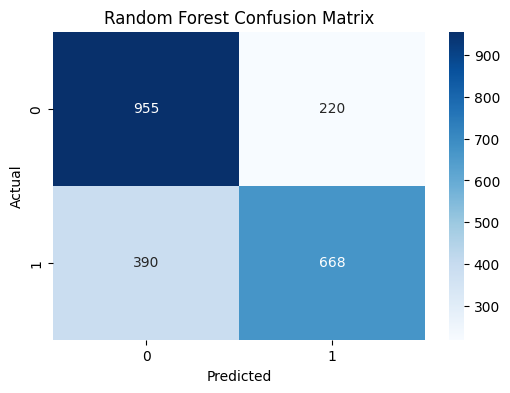

In [8]:

# ==========================================
# RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create Model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Model
rf.fit(X_train, y_train)

# Predictions
rf_preds = rf.predict(X_test)

# Evaluate Model
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(y_test, rf_preds))
print("Recall:", recall_score(y_test, rf_preds))
print("F1 Score:", f1_score(y_test, rf_preds))

print("\nClassification Report:")
print(classification_report(y_test, rf_preds))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [10]:

# ==========================================
# NEURAL NETWORK USING SGD
# ==========================================

from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD

model = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=SGD(learning_rate=0.1),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train_s,
    y_train,
    epochs=100,
    batch_size=len(X_train_s),
    verbose=0
)

nn_probs = model.predict(X_test_s, verbose=0).flatten()

nn_preds = (nn_probs >= 0.5).astype(int)

print("Neural Network Results")
print("Accuracy:", accuracy_score(y_test, nn_preds))
print("Precision:", precision_score(y_test, nn_preds))
print("Recall:", recall_score(y_test, nn_preds))
print("F1 Score:", f1_score(y_test, nn_preds))


Neural Network Results
Accuracy: 0.6927899686520376
Precision: 0.7188235294117648
Recall: 0.5775047258979206
F1 Score: 0.640461215932914


In [11]:

# ==========================================
# VOTING ENSEMBLE
# ==========================================

# Random Forest Probabilities
rf_probs = rf.predict_proba(X_test)[:, 1]

# Neural Network Probabilities
nn_probs = model.predict(X_test_s, verbose=0).flatten()

# Combine Predictions
voting_preds_proba = (rf_probs + nn_probs) / 2

# Final Predictions
voting_preds = (voting_preds_proba >= 0.5).astype(int)

# Evaluation
print("Voting Ensemble Results")

print("Accuracy:", accuracy_score(y_test, voting_preds))
print("Precision:", precision_score(y_test, voting_preds))
print("Recall:", recall_score(y_test, voting_preds))
print("F1 Score:", f1_score(y_test, voting_preds))

print("\nClassification Report:")
print(classification_report(y_test, voting_preds))


Voting Ensemble Results
Accuracy: 0.7214509628302732
Precision: 0.7564705882352941
Recall: 0.6077504725897921
F1 Score: 0.6740041928721174

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.82      0.76      1175
           1       0.76      0.61      0.67      1058

    accuracy                           0.72      2233
   macro avg       0.73      0.72      0.72      2233
weighted avg       0.73      0.72      0.72      2233

